# Computer Vision - P3

### *Carefully read the following instructions before start coding.*

==============================================================================================
## **Practice 3: Image and Video Segmentation & Templeta Matching**

==============================================================================================

### The main topics of P3 are:

- Image segmentation.

- Background subtraction.

- Template Matching





In [40]:
#
# First, let's load some libraries used in the practice
#
# Example
import numpy as np
import skimage
from skimage import io
import matplotlib.pyplot as plt
import matplotlib.animation as animation

## **Image Segmentation**

In this section we will apply different image segmentation methods (e.g., Felzenswhalbs, Slic and Quickshift) based on the clustering of points corresponding to the pixels and analyze their differences.

**Hint**: 
- Different image segmentation methods are available in [`skimage.segmentation`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html).
- Use the function [`segmentation.mark_boundaries`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.mark_boundaries) to visualize the boundaries of the segments.
- Use the inline pluggin to visualize images (`%matplotlib inline`).

<img src="images_p3/image_Segmentation.png" width=600>

### **Felzenszwalb Image Segmentation**

**a)** Apply the Felzenszwalb segmentation method to `images/hogwarts.jpeg` using `scale=100`, `sigma=0.5`, and `min_size=50`.
- Visualize the segmentation results using `mark_boundaries` to highlight segment boundaries.
- Count the number of segments detected.
- Experiment with different parameter values and analyze their effects on the segmentation results.

Expected result is illustrated below:

<img src="images_p3/bunch-of-fresh-fruit_resut.jpg" width=700>

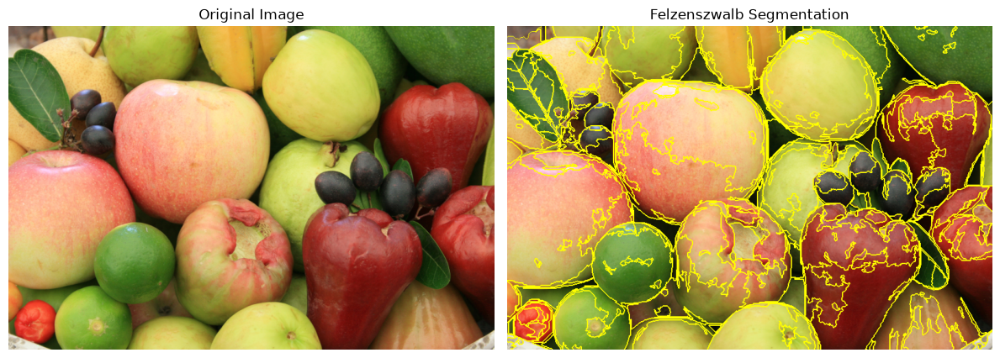

Number of segments: 446


In [41]:
# Import necessary libraries
import numpy as np
from skimage import io
from skimage.segmentation import felzenszwalb, mark_boundaries
import matplotlib.pyplot as plt

# Read the image
image = io.imread('images_p3/bunch-of-fresh-fruit.png')

# Apply Felzenszwalb segmentation
segments_fz = felzenszwalb(image, scale=100, sigma=0.5, min_size=50)

# Show the segmentation result
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Original image
ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis('off')

# Image with marked boundaries
ax[1].imshow(mark_boundaries(image, segments_fz))
ax[1].set_title("Felzenszwalb Segmentation")
ax[1].axis('off')

plt.tight_layout()
plt.show()

# Print the number of segments found
print(f'Number of segments: {len(np.unique(segments_fz))}')

**b) Exploring Felzenszwalb Segmentation Parameters**

Create a function to explore at least three different parameter combinations for the Felzenszwalb segmentation method using the image `images_p3/bunch-of-fresh-fruit.png`. 
- The function should receive the input image and a list of parameter combinations, resize the image to one-third of its original dimensions, visualize the segmentation results with marked boundaries, and print the number of segments detected for each combination.

Experiment with different values of `scale`, `sigma`, and `min_size` to identify the combination that produces the best segmentation results.

**Reflect on the following questions:**

- Is converting the image to grayscale necessary for image segmentation?
- Is converting the image to floating-point format necessary?
- Which parameter combination produces the best results according to your subjective assessment?
- How does each parameter (`scale`, `sigma`, and `min_size`) affect the segmentation results?
- Does reducing the image resolution affect the optimal parameter values? Explain why.

Expected result is illustrated below (you don't need to use the same parameters):

<img src="images_p3/bunch-of-fresh-fruit_resut2.jpg" width=800>

Scale: 50, Sigma: 0.5, Min size: 100 -> Segments: 106
Scale: 100, Sigma: 0.8, Min size: 50 -> Segments: 126
Scale: 150, Sigma: 1.0, Min size: 150 -> Segments: 59


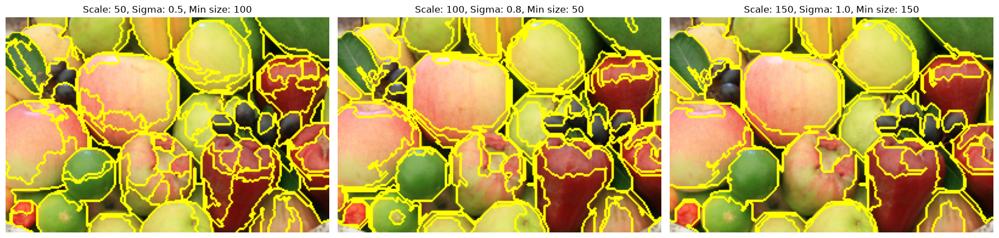

In [42]:
import numpy as np
from skimage import io, segmentation, transform, img_as_float
import matplotlib.pyplot as plt

def explore_felzenszwalb(image_path, params_list):
    # Read and resize the image
    image = io.imread(image_path)
    image_resized = transform.resize(image, (image.shape[0] // 3, image.shape[1] // 3),
                                     anti_aliasing=True)
    
    # Convert image to float (since some functions require this format)
    image_resized_float = img_as_float(image_resized)
    
    # Loop through the parameter combinations
    fig, axes = plt.subplots(1, len(params_list), figsize=(18, 6))
    
    for i, params in enumerate(params_list):
        # Apply Felzenszwalb segmentation with given parameters
        segments = segmentation.felzenszwalb(image_resized_float, **params)
        
        # Plot the result
        axes[i].imshow(segmentation.mark_boundaries(image_resized_float, segments))
        axes[i].set_title(f"Scale: {params['scale']}, Sigma: {params['sigma']}, Min size: {params['min_size']}")
        axes[i].axis('off')
        
        # Print the number of segments
        print(f"Scale: {params['scale']}, Sigma: {params['sigma']}, Min size: {params['min_size']} -> Segments: {len(np.unique(segments))}")
    
    plt.tight_layout()
    plt.show()

# Parameter combinations to explore
param_combinations = [
    {'scale': 50, 'sigma': 0.5, 'min_size': 100},
    {'scale': 100, 'sigma': 0.8, 'min_size': 50},
    {'scale': 150, 'sigma': 1.0, 'min_size': 150}
]

# Call the function
explore_felzenszwalb('images_p3/bunch-of-fresh-fruit.png', param_combinations)

### Questions and Answers:

1. **Is it critical to convert the image to grayscale to do the image segmentation?**
   - No, it is not critical to convert the image to grayscale. Felzenszwalb's algorithm can work with color images (RGB), and often using RGB provides better segmentation because it utilizes the color information to distinguish regions.

2. **Is it critical to convert the image to float to do the image segmentation?**
   - Yes, for many segmentation algorithms (including Felzenszwalb), the image needs to be in floating-point format. The pixel values need to be normalized between 0 and 1 for the algorithm to work correctly.

3. **Which are the optimal values according to your subjective perception?**
   - The optimal values depend on the specific image. However, for the given image, a scale of 100, sigma of 0.8, and a minimum size of 50 might balance between over-segmentation (too many small regions) and under-segmentation (too few large regions).

4. **How does each parameter behave?**
   - **Scale**: Larger scale values result in larger segments, merging more pixels together. A small scale leads to finer, more detailed segments.
   - **Sigma**: This controls the Gaussian smoothing applied before segmentation. Higher sigma values tend to blur the image more, reducing noise but also potentially losing some details.
   - **Min size**: This ensures that segments below a certain size are merged into neighboring segments. Larger values reduce over-segmentation by eliminating small regions.

5. **Does the image reduction affect the optimal values?**
   - Yes, reducing the image size affects the segmentation results because smaller images have less detail, which may require tuning the parameters differently (e.g., a larger `min_size` may be needed for smaller images to avoid over-segmentation). Optimal values need to be adjusted depending on the resolution and detail of the image.

### **SLIC — K-Means-Based Image Segmentation**

**c)** Segment the image `images_p3/bunch-of-fresh-fruit.png` using the SLIC algorithm implemented in [`skimage.segmentation.slic`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.slic).

1. Apply SLIC using the following parameters: `n_segments=250`, `compactness=10`, `sigma=1`, and `start_label=1`.
2. Visualize the original image alongside the segmented image, using [`mark_boundaries`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.mark_boundaries) to highlight the boundaries between segments.
3. Print the total number of segments detected.

Expected result is illustrated below:

<img src="images_p3/bunch-of-fresh-fruit_resut3.jpg" width=800>


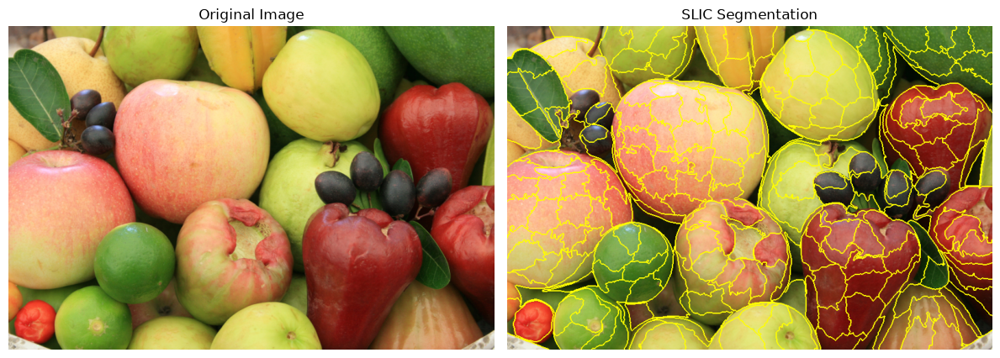

Number of segments: 219


In [43]:
# Import necessary libraries
from skimage import io, segmentation, color
import matplotlib.pyplot as plt
import numpy as np

# Read the image
image = io.imread('images_p3/bunch-of-fresh-fruit.png')

# Apply SLIC segmentation with default parameters
segments_slic = segmentation.slic(image, n_segments=250, compactness=10, sigma=1, start_label=1)

# Convert the image to a format suitable for marking boundaries
image_boundaries = segmentation.mark_boundaries(image, segments_slic)

# Show the original image and the SLIC segmented image
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Original image
ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis('off')

# Image with marked boundaries
ax[1].imshow(image_boundaries)
ax[1].set_title("SLIC Segmentation")
ax[1].axis('off')

plt.tight_layout()
plt.show()

# Print the number of segments found
print(f'Number of segments: {len(np.unique(segments_slic))}')

**d)** Create a function to explore at least three different parameter combinations for the SLIC segmentation algorithm.
- Identify the combination that produces the best results. 
- The function should receive the input image and a list of parameter combinations, resize the image to one-third of its original dimensions, visualize the segmentation results with marked boundaries, and print the number of segments detected for each combination.

Expected result is illustrated below (you don't need to use the same parameters):

<img src="images_p3/bunch-of-fresh-fruit_resut4.jpg" width=800>

n_segments: 100, Compactness: 10, Sigma: 1 -> Segments: 70
n_segments: 200, Compactness: 20, Sigma: 1 -> Segments: 197
n_segments: 300, Compactness: 30, Sigma: 1 -> Segments: 266


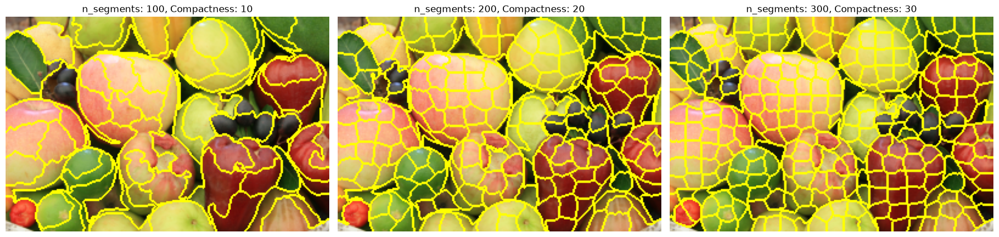

In [44]:
from skimage import io, segmentation, transform, img_as_float
import matplotlib.pyplot as plt
import numpy as np

def explore_slic(image_path, params_list):
    # Read the image
    image = io.imread(image_path)
    
    # Resize the image to one-third of its original size
    image_resized = transform.resize(image, (image.shape[0] // 3, image.shape[1] // 3),
                                     anti_aliasing=True)
    
    # Convert the image to float format
    image_resized_float = img_as_float(image_resized)
    
    # Loop through the parameter combinations
    fig, axes = plt.subplots(1, len(params_list), figsize=(18, 6))
    
    for i, params in enumerate(params_list):
        # Apply SLIC segmentation with the given parameters
        segments_slic = segmentation.slic(image_resized_float, **params)
        
        # Plot the result with marked boundaries
        axes[i].imshow(segmentation.mark_boundaries(image_resized_float, segments_slic))
        axes[i].set_title(f"n_segments: {params['n_segments']}, Compactness: {params['compactness']}")
        axes[i].axis('off')
        
        # Print the number of segments
        print(f"n_segments: {params['n_segments']}, Compactness: {params['compactness']}, Sigma: {params['sigma']} -> Segments: {len(np.unique(segments_slic))}")
    
    plt.tight_layout()
    plt.show()

# Define parameter combinations to explore
param_combinations = [
    {'n_segments': 100, 'compactness': 10, 'sigma': 1},
    {'n_segments': 200, 'compactness': 20, 'sigma': 1},
    {'n_segments': 300, 'compactness': 30, 'sigma': 1}
]

# Call the function with the image and parameter combinations
explore_slic('images_p3/bunch-of-fresh-fruit.png', param_combinations)

### **Quickshift Image Segmentation**

**e)** Apply the [Quickshift segmentation algorithm](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.quickshift) to the original image, `images_p3/bunch-of-fresh-fruit.png`.

- Create a function that explores different `kernel_size` values (`1`, `3`, `5`, and `7`), keeping `max_dist=6` and `ratio=0.5` fixed. 
- For each value, visualize the segmentation results with marked boundaries using [`mark_boundaries`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.mark_boundaries) and print the number of segments detected.

Expected result is illustrated below:

<img src="images_p3/bunch-of-fresh-fruit_resut5.jpg" width=800>


Kernel size: 1 -> Segments: 6727
Kernel size: 3 -> Segments: 1427
Kernel size: 5 -> Segments: 683
Kernel size: 7 -> Segments: 492


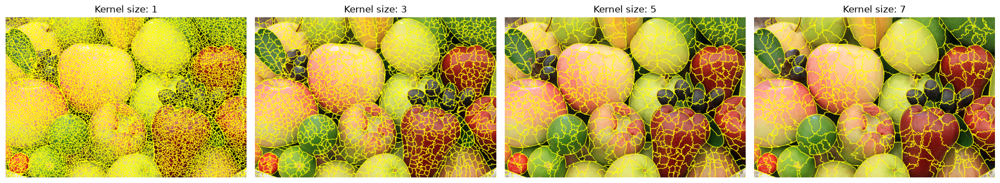

In [45]:
# Import necessary libraries
from skimage import io, segmentation, color
import matplotlib.pyplot as plt
import numpy as np

def explore_quickshift(image_path, kernel_sizes):
    # Read the original image
    image = io.imread(image_path)
    
    # Loop through the different kernel_size values
    fig, axes = plt.subplots(1, len(kernel_sizes), figsize=(18, 6))
    
    for i, kernel_size in enumerate(kernel_sizes):
        # Apply Quickshift segmentation with varying kernel_size
        segments_quickshift = segmentation.quickshift(image, kernel_size=kernel_size, max_dist=6, ratio=0.5)
        
        # Plot the result
        axes[i].imshow(segmentation.mark_boundaries(image, segments_quickshift))
        axes[i].set_title(f"Kernel size: {kernel_size}")
        axes[i].axis('off')
        
        # Print the number of segments
        print(f"Kernel size: {kernel_size} -> Segments: {len(np.unique(segments_quickshift))}")
    
    plt.tight_layout()
    plt.show()

# Define kernel_size values to explore
kernel_sizes = [1, 3, 5, 7]

# Call the function with the image and kernel_size values
explore_quickshift('images_p3/bunch-of-fresh-fruit.png', kernel_sizes)

### **Comparison of Image Segmentation Algorithms**

**f)** Select the best parameter settings for the Felzenszwalb and SLIC segmentation algorithms based on your previous experiments. 

Apply both algorithms to the following three versions of `images_p3/bunch-of-fresh-fruit.png`:

1. **Original image:** Use the image without modifications.
2. **Salt-and-pepper noise:** Add noise using `util.random_noise(image, mode='s&p', amount=0.05)`.
3. **Smoothed noisy image:** Apply a Gaussian smoothing filter to the noisy image using `filters.gaussian` with `sigma=2`.

Visualize the segmentation results using `mark_boundaries`. Arrange the results in a \(2 x 3\) subplot grid, with one row for each algorithm and one column for each image version. Print the number of segments detected in each case.

**Reflect on the results:** How does salt-and-pepper noise affect segmentation? Does Gaussian smoothing improve the results? Which algorithm is more robust to noise, and why?

Expected result is illustrated below (**feel free to fine tune the parameters for best results**):

<img src="images_p3/bunch-of-fresh-fruit_resut6.jpg" width=1000>

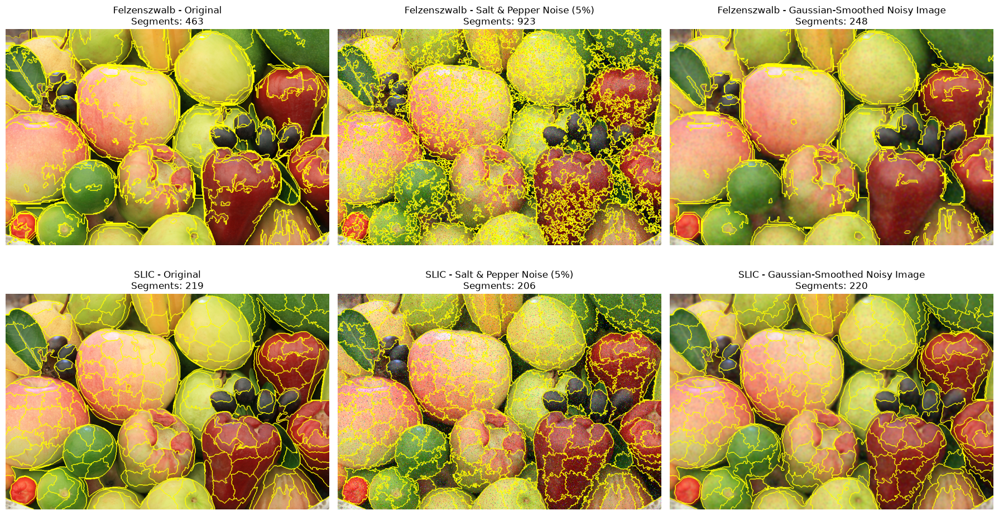

In [46]:

from skimage import io, segmentation, util, filters
import matplotlib.pyplot as plt
import numpy as np

# Define the best parameters for each algorithm
felzenszwalb_params = {
    'scale': 100,
    'sigma': 0.8,
    'min_size': 50
}

slic_params = {
    'n_segments': 250,
    'compactness': 10,
    'sigma': 1
}


# Function to create image variations
def transform_images(image):
    # Add salt-and-pepper noise
    salt_pepper = util.random_noise(
        image, mode='s&p', amount=0.05
    )

    # Apply Gaussian smoothing to the noisy image
    smoothed = filters.gaussian(
        salt_pepper, sigma=2, channel_axis=-1
    )

    return salt_pepper, smoothed


# Function to compare segmentation algorithms
def compare_segmentation(image, felzenszwalb_params, slic_params):
    salt_pepper, smoothed = transform_images(image)

    images = [
        ("Original", image),
        ("Salt & Pepper Noise (5%)", salt_pepper),
        ("Gaussian-Smoothed Noisy Image", smoothed)
    ]

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))

    for i, (name, img) in enumerate(images):

        # Felzenszwalb segmentation
        felz_segments = segmentation.felzenszwalb(
            img, **felzenszwalb_params
        )

        axes[0, i].imshow(
            segmentation.mark_boundaries(img, felz_segments)
        )
        axes[0, i].set_title(
            f"Felzenszwalb - {name}\n"
            f"Segments: {len(np.unique(felz_segments))}"
        )
        axes[0, i].axis('off')

        # SLIC segmentation
        slic_segments = segmentation.slic(
            img, **slic_params
        )

        axes[1, i].imshow(
            segmentation.mark_boundaries(img, slic_segments)
        )
        axes[1, i].set_title(
            f"SLIC - {name}\n"
            f"Segments: {len(np.unique(slic_segments))}"
        )
        axes[1, i].axis('off')

    plt.tight_layout()
    plt.show()


# Read the original image
image = io.imread('images_p3/bunch-of-fresh-fruit.png')

# Compare segmentation results
compare_segmentation(
    image, felzenszwalb_params, slic_params
)


**Reflect on the results:**

- **Effect of salt-and-pepper noise:** It introduces random bright and dark pixels, creating irregular boundaries and often increasing the number of segments, especially for Felzenszwalb.
- **Effect of Gaussian smoothing:** It generally reduces noise and produces cleaner segments, but excessive smoothing can blur object boundaries.
- **Robustness:** SLIC is often more robust because it considers both color similarity and spatial proximity, producing more regular regions. However, robustness depends on the parameter settings and image content.


### **Hierarchical Clustering for Image Segmentation**

In this exercise, you will use **hierarchical clustering** to segment the grayscale image `images_p3/groot.jpg`.

First, load the image, convert it to grayscale, and display it. Then, apply scikit-learn’s [`AgglomerativeClustering`](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html) to group pixels into 10 clusters and visualize the segmentation results side by side with the original grayscale image.

**Hints:**
- Convert the grayscale image into a 2D array where each row represents one pixel and contains its intensity value. This is necessary because `AgglomerativeClustering.fit(X)` expects a 2D array with shape (n_samples, n_features), where each pixel is a sample and its grayscale intensity is the feature.
- Use `AgglomerativeClustering` with Ward’s linkage (`linkage='ward'`) and set the number of clusters to 10.
- Use [`grid_to_graph`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.image.grid_to_graph.html) to define the connectivity matrix, preserving the spatial relationships between neighboring pixels.
- Reshape the resulting cluster labels back to the original image dimensions and display the segmented image using a suitable colormap.

Expected result is illustrated below:

<img src="images_p3/groot_result.jpg" width=800>

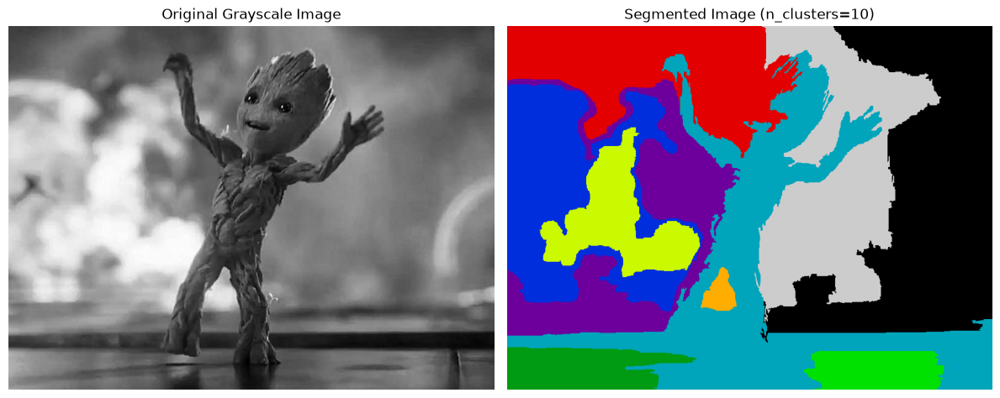

In [47]:
import numpy as np
from skimage import io, color
from sklearn.cluster import AgglomerativeClustering
from sklearn.feature_extraction.image import grid_to_graph
import matplotlib.pyplot as plt

# Load the image and convert it to grayscale
image = io.imread('images_p3/groot.jpg')
gray_image = color.rgb2gray(image)

# Reshape the image into a 2D array of pixels
shape = gray_image.shape
X = gray_image.reshape(-1, 1)  # Reshape to a 2D array of (n_samples, 1)

# Create a connectivity matrix
connectivity = grid_to_graph(n_x=shape[0], n_y=shape[1])

# Apply hierarchical clustering (Ward's method)
n_clusters = 10  # Define the number of clusters for segmentation
clustering = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward', connectivity=connectivity)
clustering.fit(X)

# Reshape the labels back to the original image shape
labels = clustering.labels_.reshape(shape)

# Plot the original image and the segmented image side by side
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Display original grayscale image
ax[0].imshow(gray_image, cmap='gray')
ax[0].set_title("Original Grayscale Image")
ax[0].axis('off')

# Display segmented image (using labels as segments)
ax[1].imshow(labels, cmap='nipy_spectral')
ax[1].set_title(f"Segmented Image (n_clusters={n_clusters})")
ax[1].axis('off')

plt.tight_layout()
plt.show()

---

## **Background Subtraction for Motion Detection**

In this exercise, you will implement a background subtraction algorithm using Python, NumPy, and Matplotlib to detect moving objects in video frames.

The images are organized into two folders: `images_p3/vip_cup_2020/train` and `images_p3/vip_cup_2020/test`. Use the 100 frames from the `train` folder to estimate the background model, and the frames in the `test` folder to detect moving objects by comparing each frame with the estimated background.

Your program must perform the following tasks:

**Step 1**

1. **Load the sequence frames:** Load the first 100 images from the `images_p3/vip_cup_2020/train` folder to build the background model. Reduce each frame by 50% to reduce memory usage and processing time. Ensure that the training and test frames have the same dimensions.

2. **Compute the background image:** Implement a function called `compute_background(frames)` that stacks the first 100 training frames into a NumPy array and calculates the median pixel value along the temporal axis to estimate the static background.

3. **Visualize the background model:** Display the estimated background image.

**Step 2**

4. **Extract the foreground:** Implement a function called `subtract_background(test_frame, background_image, threshold=30)` that calculates the absolute difference between each test frame and the estimated background. Apply a threshold to identify pixels that differ significantly from the background.

5. **Visualize the moving objects:** For a selected test frame, show the original frame and the extracted foreground image side by side using Matplotlib.




### Step 1 — Load training frames and generate the background model

In the following cell, implement the code to load the first 100 training images, resize them to 50% of their original dimensions, compute the background model using the temporal median, and display the resulting background image.

Expected result is illustrated below:

<img src="images_p3/bkg_model.jpg" width=400>

Training frames loaded: 100
Resized dimensions: (512, 512, 3)
Background model generated successfully.


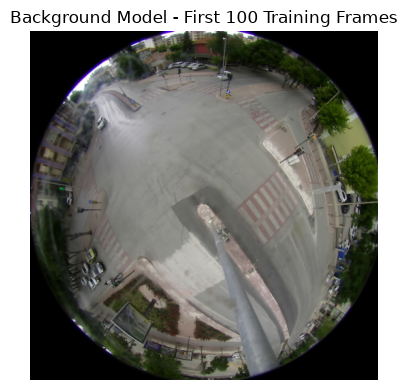

In [48]:

import numpy as np
import matplotlib.pyplot as plt
from skimage import io
from skimage.transform import resize
from pathlib import Path

# --------------------------------------------------
# Step 1: Load the first 100 training frames
# --------------------------------------------------

train_folder = Path("images_p3/vip_cup_2020/train")
test_folder = Path("images_p3/vip_cup_2020/test")

train_paths = sorted(train_folder.glob("*.jpg"))[:100]

if len(train_paths) != 100:
    raise ValueError(
        f"Expected 100 training images, found {len(train_paths)}."
    )

def resize_frame(frame):
    """Reduce frame width and height by 50%."""
    height, width = frame.shape[:2]

    return resize(
        frame,
        (height // 2, width // 2),
        preserve_range=True,
        anti_aliasing=True
    ).astype(np.uint8)

# Load and resize training frames
train_frames = [
    resize_frame(io.imread(path))
    for path in train_paths
]

# Ensure all training frames have the same dimensions
if len({frame.shape for frame in train_frames}) != 1:
    raise ValueError("Training frames have inconsistent dimensions.")

print(f"Training frames loaded: {len(train_frames)}")
print(f"Resized dimensions: {train_frames[0].shape}")


# --------------------------------------------------
# Step 2: Compute the background using the median
# --------------------------------------------------

def compute_background(frames):
    """Estimate the background using the temporal median."""
    frame_stack = np.stack(frames, axis=0)
    background = np.median(frame_stack, axis=0)

    return background.astype(np.uint8)

background_image = compute_background(train_frames)

print("Background model generated successfully.")


# --------------------------------------------------
# Step 3: Display the background model
# --------------------------------------------------

plt.figure(figsize=(6, 4))
plt.imshow(background_image)
plt.title("Background Model - First 100 Training Frames")
plt.axis("off")
plt.tight_layout()
plt.show()


### Step  2 — Detect and visualize moving objects in test frames
In the following cell, implement the code to load and resize the test images, subtract the estimated background model, generate binary foreground masks, and display the background model, original test frames, and detected moving objects side by side.

Expected result, for two test images, is illustrated below:

<img src="images_p3/bkg_test.jpg" width=750>

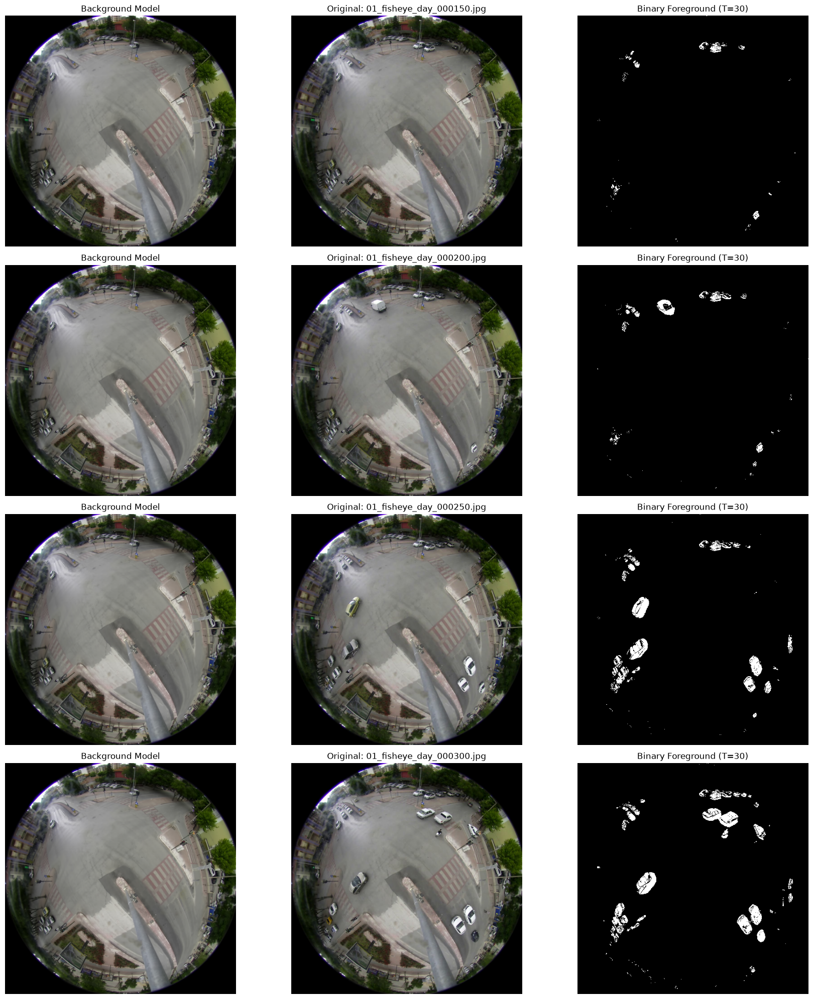

In [49]:

import numpy as np
import matplotlib.pyplot as plt
from skimage import io
from pathlib import Path

# --------------------------------------------------
# Step 4: Background subtraction
# --------------------------------------------------

def subtract_background(test_frame, background_image, threshold=30):
    """Return a binary mask of detected foreground pixels."""

    difference = np.abs(
        test_frame.astype(np.int16) -
        background_image.astype(np.int16)
    )

    # True = foreground, False = background
    mask = np.max(difference, axis=2) > threshold

    return mask


# --------------------------------------------------
# Step 5: Select four test images
# --------------------------------------------------

test_folder = Path("images_p3/vip_cup_2020/test")
test_paths = sorted(test_folder.glob("*.jpg"))

if len(test_paths) < 4:
    raise ValueError(
        f"At least 4 test images are required; found {len(test_paths)}."
    )

# Select four evenly spaced images
selected_indices = np.linspace(
    0, len(test_paths) - 1, 4, dtype=int
)

threshold = 30


# --------------------------------------------------
# Step 6: Display background, original, and binary mask
# --------------------------------------------------

fig, ax = plt.subplots(4, 3, figsize=(18, 20))

for row, index in enumerate(selected_indices):

    # Load and resize the test image
    image_path = test_paths[index]
    test_frame = resize_frame(io.imread(image_path))

    # Check dimensions
    if test_frame.shape != background_image.shape:
        raise ValueError(
            f"Frame {image_path.name} does not match "
            "the background dimensions."
        )

    # Detect foreground pixels
    mask = subtract_background(
        test_frame,
        background_image,
        threshold=threshold
    )

    # Column 1: Background model
    ax[row, 0].imshow(background_image)
    ax[row, 0].set_title("Background Model")
    ax[row, 0].axis("off")

    # Column 2: Original test frame
    ax[row, 1].imshow(test_frame)
    ax[row, 1].set_title(f"Original: {image_path.name}")
    ax[row, 1].axis("off")

    # Column 3: Binary foreground mask
    ax[row, 2].imshow(
        mask.astype(np.uint8),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax[row, 2].set_title(f"Binary Foreground (T={threshold})")
    ax[row, 2].axis("off")

plt.tight_layout()
plt.show()


---

## **Template Matching**

**a)** Given the image `images_p3/einstein.png` and the template image `images_p3/eye.png`, locate the template within the original image by implementing and comparing the following methods:

- **Sum of Squared Differences (SSD):** Use `norm()` from `numpy.linalg` to calculate the distance between the template and candidate image regions.
- **Normalized Cross-Correlation (NCC):** Use `match_template()` from `skimage.feature` to measure the similarity between the template and candidate image regions.

Before performing the comparisons, normalize both images so that their pixel values lie within the range \([0, 1]\).

Compare the results obtained with both methods and visualize the detected template location in the original image.


Expected result, for two test images, is illustrated below:

<img src="images_p3/einstein_result1.jpg" width=800>

***Note:*** the decision of threshold for SSD distance and normalized cross-correlation will affect your results, try values that get you as close to the shown result as possible.

In [50]:
# Your solution here
import numpy as np
from skimage import io, color, transform, feature, measure
import matplotlib.pyplot as plt


def ensure_gray(image):
    if image.ndim == 3:
        if image.shape[-1] == 4:
            image = color.rgba2rgb(image)
        if image.shape[-1] == 3:
            return color.rgb2gray(image)
    return image

def normalize(image):
    if image.max() > 1.:
        image = image.astype(np.float32) / 255.
    return image

def get_connected_component_centroids(binary_image):
    labeled_image = measure.label(binary_image)
    properties = measure.regionprops(labeled_image)
    centroids = []
    for prop in properties:
        centroids.append((int(prop.centroid[1]), int(prop.centroid[0])))  # (x, y)
    return centroids

# ssd distance
def ssd_template_matching(image, template, threshold=0.5):
    h_img, w_img = image.shape
    h_tpl, w_tpl = template.shape
    # The result map will have dimensions (H_img - H_tpl + 1, W_img - W_tpl + 1)
    h_res, w_res = h_img - h_tpl + 1, w_img - w_tpl + 1
    ssd_result = np.zeros((h_res, w_res), dtype=np.float64)

    # This loop is still necessary but the inner calculations are vectorized by numpy
    for y in range(h_res):
        for x in range(w_res):
            # Extract the current window from the image
            window = image[y:y+h_tpl, x:x+w_tpl]
            # Calculate the Sum of Squared Differences (SSD) for this window
            diff = window - template
            squared_diff = diff**2
            # Sum all elements in the squared difference matrix
            current_ssd = np.sum(squared_diff)
            
            ssd_result[y, x] = current_ssd
    # For SSD, the best match is the MINIMUM value
    thresholded = np.zeros_like(ssd_result).astype(np.uint8)
    thresholded[ssd_result < threshold] = 1

    # we want to get the central locations of each connected component
    locations = get_connected_component_centroids(thresholded)

    return locations, ssd_result, thresholded

def ncc_template_matching(image, template, threshold=0.5):
    ncc_result = feature.match_template(image, template, pad_input=False)
    # For NCC, the best match is the MAXIMUM value
    thresholded = np.zeros_like(ncc_result).astype(np.uint8)
    thresholded[ncc_result > threshold] = 1
    locations = get_connected_component_centroids(thresholded)
    return locations, ncc_result, thresholded

def plot_template_matching(image, template, locations, result_map, thresholded, title):
    # Get the coordinates for drawing the rectangle
    w, h = template.shape[::-1] # Template width and height
    fig, axes = plt.subplots(1, 4, figsize=(13, 4), sharex=False, sharey=False)
    ax = axes.ravel()
    ax[0].imshow(template, cmap=plt.cm.gray)
    ax[0].set_title('Template')
    ax[0].set_axis_off()

    ax[1].imshow(image, cmap=plt.cm.gray)
    ax[1].set_title('Source Image')
    ax[1].set_axis_off()

    for top_left in locations:
        ax[1].add_patch(plt.Rectangle(top_left, w, h, edgecolor='r', facecolor='none', linewidth=2))

    ax[2].imshow(thresholded, cmap='gray')
    ax[2].set_title("Thresholded")
    ax[2].set_axis_off()
    ax[3].imshow(result_map, cmap='viridis')
    ax[3].set_title('Result Map')
    ax[3].set_axis_off()

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

def run_template_matching(image_path, template_path, ssd_threshold=65, ncc_threshold=0.6):
    if isinstance(image_path, str):
        image = ensure_gray(io.imread(image_path))
    else:
        image = ensure_gray(image_path)
    if isinstance(template_path, str):
        template = ensure_gray(io.imread(template_path))
    else:
        template = ensure_gray(template_path)
    image, template = normalize(image), normalize(template)

    ssd_locations, ssd_result_map, ssd_thresholded = ssd_template_matching(image, template, threshold=ssd_threshold)
    plot_template_matching(image, template, ssd_locations, ssd_result_map, ssd_thresholded, "SSD")

    ncc_locations, ncc_result_map, ncc_thresholded = ncc_template_matching(image, template, threshold=ncc_threshold)
    plot_template_matching(image, template, ncc_locations, ncc_result_map, ncc_thresholded, "NCC")

    return ssd_result_map, ncc_result_map


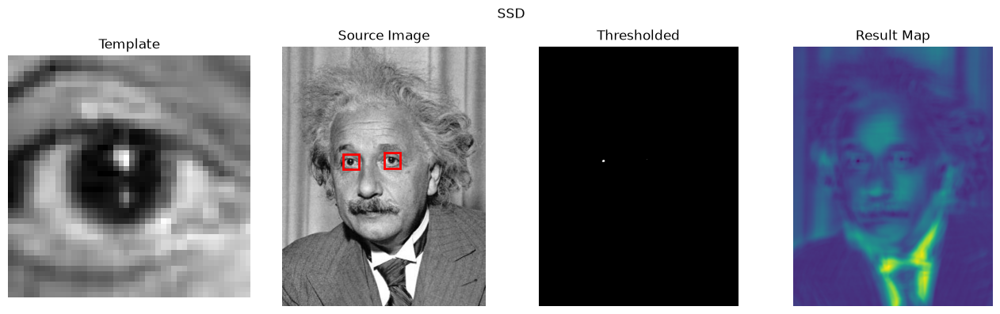

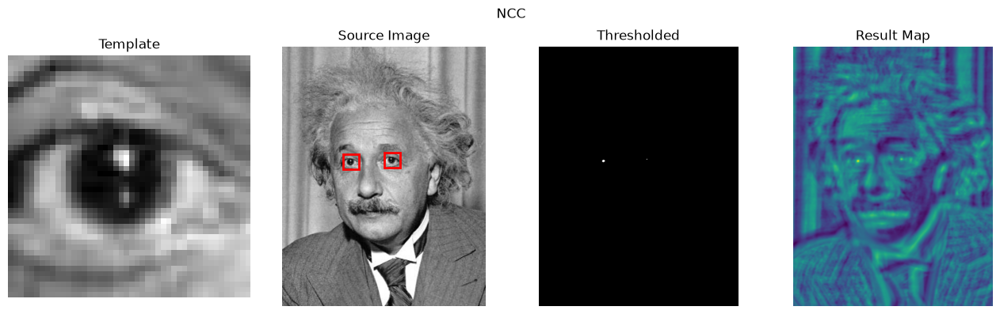

In [51]:
ssd_result_map, ncc_result_map = run_template_matching("images_p3/einstein.png", "images_p3/eye.png", ssd_threshold=65, ncc_threshold=0.6)

## Evaluating Rotation Invariance in Template Matching

Investigate how rotating the template affects the performance of the template matching methods implemented in the previous section.

- Visualize the original template and its rotated versions at angles of 2°, 5°, 10°, 15°, and 20°.
- Apply both template matching methods (SSD and normalized cross-correlation) to each rotated template and compare the results.
- Keep the threshold fixed across all experiments to ensure a fair comparison.

**Hint:** Use the `rotate()` function from `skimage.transform` to rotate the template.

Discuss how sensitive each method is to template rotation and whether either method is rotation-invariant.

Expected result, rotation = 5, is illustrated below:

<img src="images_p3/einstein_result2.jpg" width=800>

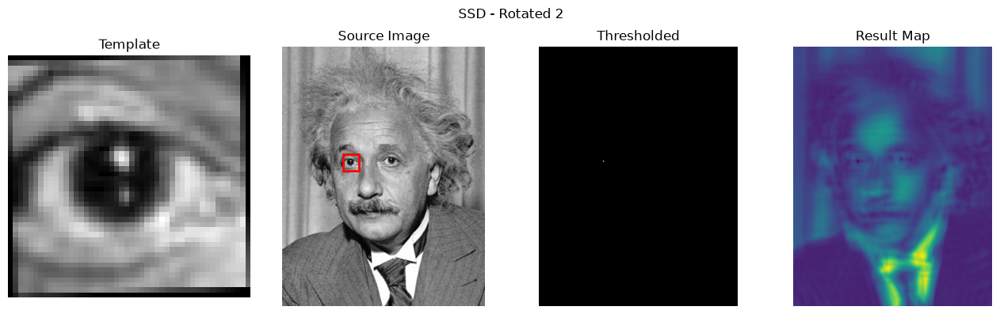

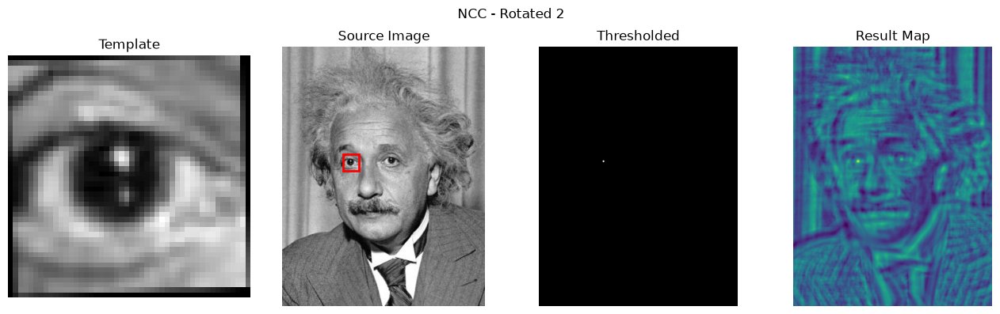

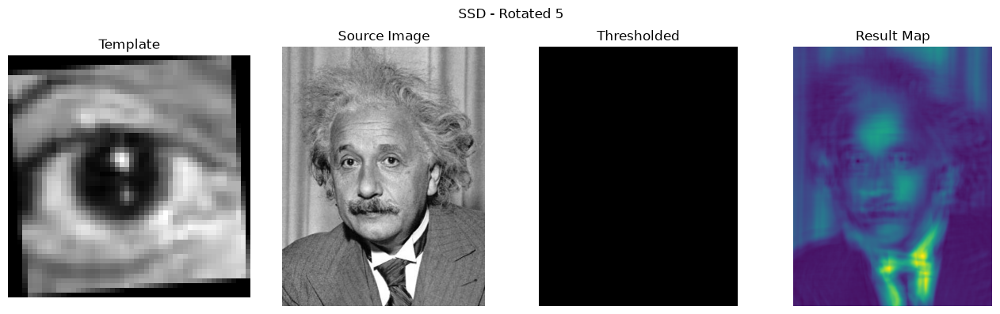

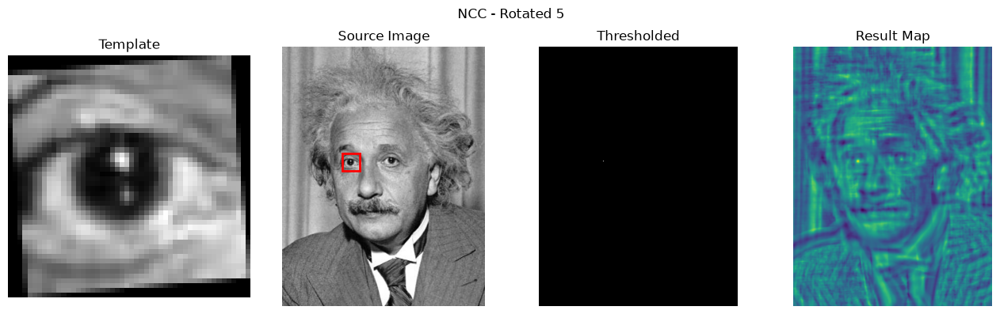

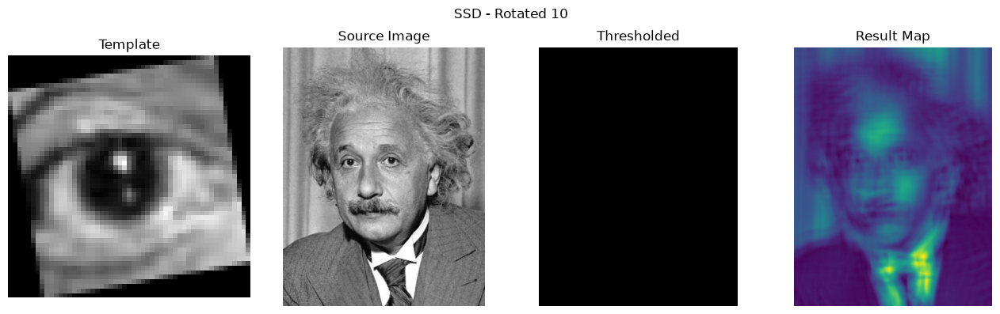

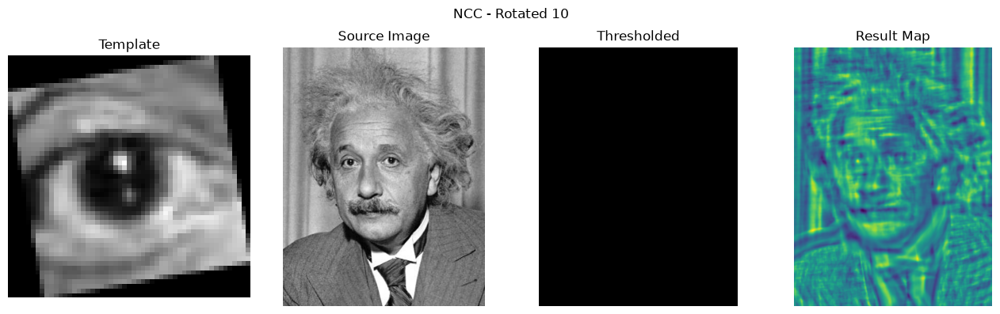

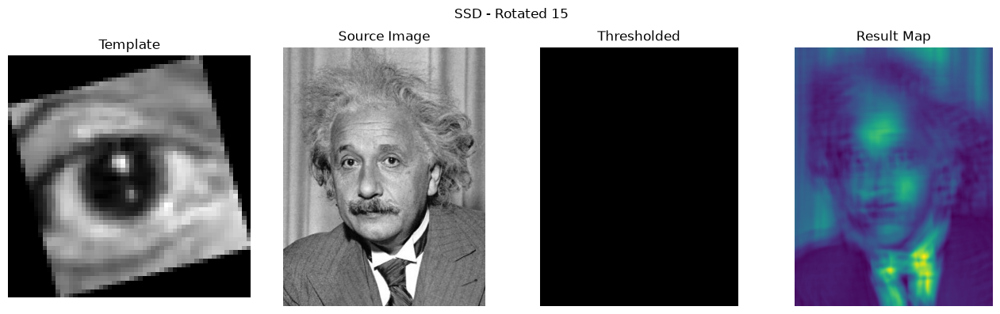

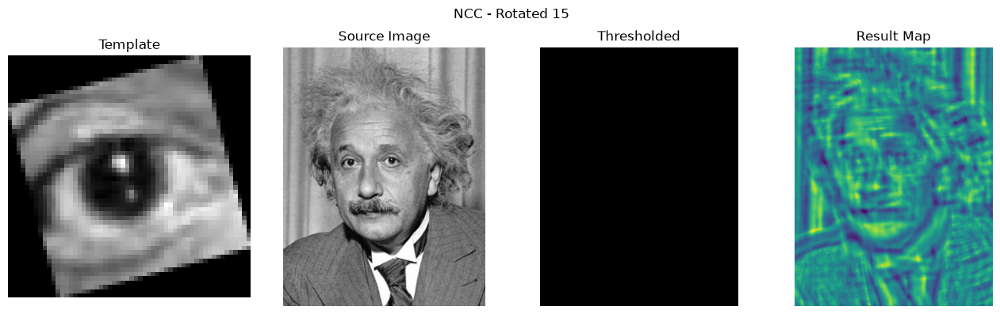

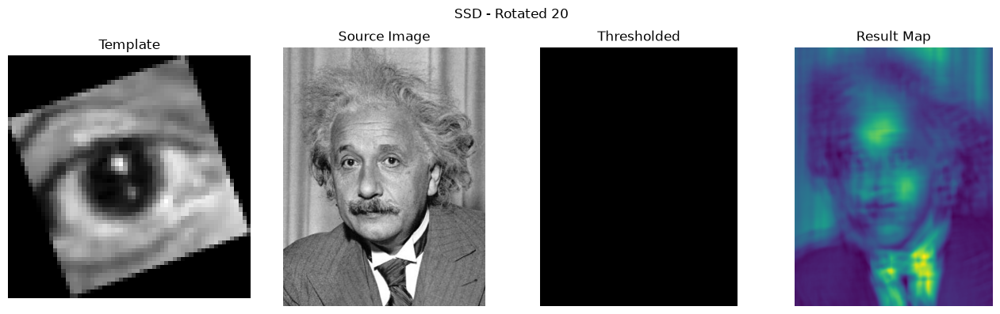

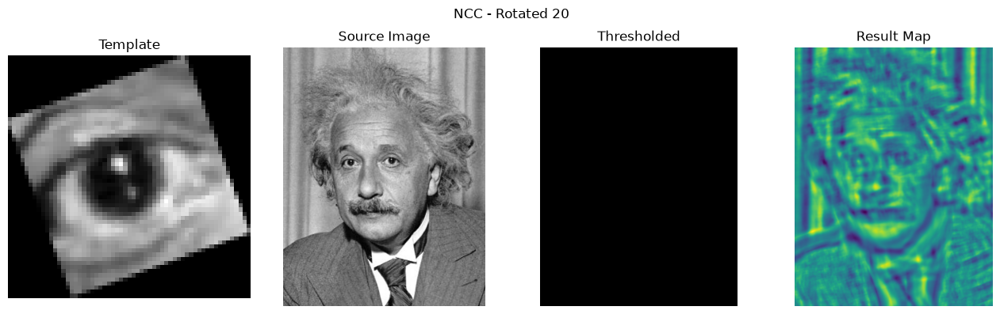

In [52]:
# Your solution here
image = ensure_gray(io.imread("images_p3/einstein.png"))
template = ensure_gray(io.imread("images_p3/eye.png"))

for angle in [2, 5, 10, 15, 20]:
    rotated_template = transform.rotate(template, angle, resize=True)
    ssd_locations, ssd_result_map, ssd_thresholded = ssd_template_matching(image, rotated_template, threshold=65)
    plot_template_matching(image, rotated_template, ssd_locations, ssd_result_map, ssd_thresholded, f"SSD - Rotated {angle}")

    ncc_locations, ncc_result_map, ncc_thresholded = ncc_template_matching(image, rotated_template, threshold=0.6)
    plot_template_matching(image, rotated_template, ncc_locations, ncc_result_map, ncc_thresholded, f"NCC - Rotated {angle}")